In [1]:
# Import the necessary libraries
from core.glacier import GlacierDynamicsCheckpointed
import torch
from utils.temperature_functions import flat_then_gelu_series,cosine_temperature_series
from core.inversion import inversion_extent,inversion_thicknes
from visualization.plots import  visualize_velocities,plot_loss_components,plot_sim_with_obs_extent
import matplotlib.pyplot as plt
from core.cnn_model import CNN
from data.loader import load_geology,load_daily_data
import pandas as pd
import numpy as np
import netCDF4


%matplotlib inline

Using device: cuda:1


In [2]:
device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')
print(device)

cuda:1


In [3]:

config = {
"nb_layers": 8,               # Number of convolutional layers
"nb_out_filter": 64,           # Number of output filters for Conv2D
"conv_ker_size": 5,            # Convolution kernel size
"activation": "lrelu",          # Activation function: "relu" or "lrelu"
"dropout_rate": 0.1,           # Dropout rate
}
nb_inputs = 3  # thk, slopsurfx, slopsurfy
nb_outputs = 2  # ubar, vbar
state = torch.load('data/emulator_model.pth', map_location=device, weights_only=False)
model = CNN(nb_inputs, nb_outputs, config).to(device)
model.load_state_dict(state, strict=True)
model.eval()

CNN(
  (model): Sequential(
    (0): Conv2d(3, 64, kernel_size=(5, 5), stride=(1, 1), padding=same)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Dropout(p=0.1, inplace=False)
    (3): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=same)
    (4): LeakyReLU(negative_slope=0.01)
    (5): Dropout(p=0.1, inplace=False)
    (6): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=same)
    (7): LeakyReLU(negative_slope=0.01)
    (8): Dropout(p=0.1, inplace=False)
    (9): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=same)
    (10): LeakyReLU(negative_slope=0.01)
    (11): Dropout(p=0.1, inplace=False)
    (12): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=same)
    (13): LeakyReLU(negative_slope=0.01)
    (14): Dropout(p=0.1, inplace=False)
    (15): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=same)
    (16): LeakyReLU(negative_slope=0.01)
    (17): Dropout(p=0.1, inplace=False)
    (18): Conv2d(64, 64, kernel_size=(5, 5), stride=(

In [4]:
data, years = load_daily_data("temp_prec.dat")         # overwrite behavior


In [5]:
Z_topo,H_init, icemask = load_geology("data/geology.nc")

In [6]:
# Z_topo=Z_topo_[100:,:]
# H_init=H_init_[100:,:]
# icemask=icemask_[100:,:]


In [7]:
dx=100
dy=100
ttot=torch.tensor(2000.0)
time=torch.tensor(1700.0)
rho, g, fd=1,1,1
precip_tensor=1.8
T_m_lowest=7.0
T_s=10.0
melt_factor=3.05/12
h_init=torch.zeros(Z_topo.shape, device=device)

In [8]:
# torch.save(H_sim,'Obs_cosine2.pt')

## Inversion

In [14]:

nc = netCDF4.Dataset('./data/geology.nc')
topo = torch.tensor(nc.variables['topg'][:], device=device)
obs_26= torch.tensor(nc.variables['surf_1880'][:], device=device) -topo
obs_57= torch.tensor(nc.variables['surf_1957'][:], device=device) -topo
obs_80= torch.tensor(nc.variables['surf_1980'][:], device=device) -topo
obs_99= torch.tensor(nc.variables['surf_1999'][:], device=device) -topo
nc.close()



In [15]:
Lx, Ly = Z_topo.shape[1] * dx, Z_topo.shape[0] * dy

glacier_model = GlacierDynamicsCheckpointed(
        Z_topo,H_init, ttot,time, rho, g, fd,
        Lx, Ly, dx, dy,dtmax=1, device=device, ice_mask=icemask,model=model
    )

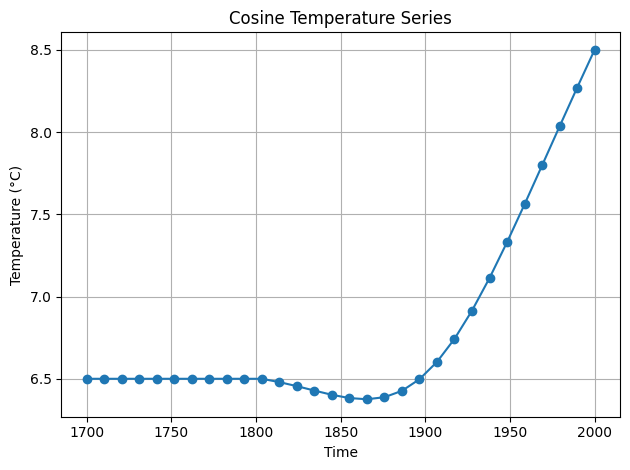

In [16]:
# series=cosine_temperature_series(319,10.0,device=device)
series=flat_then_gelu_series(int(ttot-time),10.0,flat_value=6.5,slope=2.0,sharpness=2.0,device=device)

    # Time axis aligned with the inclusive endpoint above
time_axis = torch.linspace(time, ttot, steps=series.numel())
plt.figure()
plt.plot(time_axis.numpy(), series.cpu().numpy(), marker='o')
plt.title("Cosine Temperature Series")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.tight_layout()
plt.savefig('Synthetic_temperature.png')
plt.show()


In [12]:
# obs_thk1 = torch.load('Obs_cosine1.pt',weights_only=True).to(device)
# obs_thk2 = torch.load('Obs_cosine2.pt',weights_only=True).to(device)

In [13]:
obs_26,obs_57,obs_80,obs_99 = glacier_model(precip_tensor, series, T_s,P_daily=None,T_daily=None,melt_factor=melt_factor)  # Use the checkpointed glacier model


/home/klleshi/Documents/InvertedGlacierEvolutionModel/core/glacier.py:60: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t_last_update = torch.tensor(self.time, device=self.device)
/home/klleshi/miniconda3/envs/IGEM/lib/python3.12/site-packages/torch/_dynamo/eval_frame.py:632: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In version 2.5 we will raise an exception if use_reentrant is not passed. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/home/klleshi/miniconda3/envs/IGEM/lib/python3.12/site-packages/torch/utils/checkpoint.py:87: UserWarning: None of the inputs have requires_grad=True. Gradients will be No

KeyboardInterrupt: 

In [17]:
# Early stopping parameters
early_stop_patience = 1
early_stop_threshold = 1e-5
# Internal early stopping stateobs
best_loss = float('inf')
no_improve_count = 0

# _,obs, _ = load_geology("data/geology.nc")


# precip_tensor = torch.full(Z_topo.shape,1.3,requires_grad=False,device=device)
# precip_tensor = torch.tensor(precip_tensor,requires_grad=False,device=device)
T_m_lowest = torch.full((len(series),1),6.649464607238769, requires_grad=True, device=device)
# T_m_lowest = torch.tensor(6.5, requires_grad=True, device=device)

# T_s = torch.tensor(10.0, requires_grad=False, device=device)

P_daily_=data[:,:,1]/1000
T_daily_=data[:,:,0]+13.762
# melt_factor= torch.tensor(1.5/365, requires_grad=True, device=device)


optimizer = torch.optim.Adam([T_m_lowest], lr=0.01)
loss_hist, Precip_history, data_hist = [], [], []
results = []
for i in range(50):  # n_iterations
    optimizer.zero_grad()
    
    # # Force positivity with softplus
    # melt_factor = F.relu(melt_factor_raw)

    H_simulated, loss = inversion_thicknes(precip_tensor,T_m_lowest,T_s,P_daily=P_daily_,T_daily=T_daily_, melt_factor=melt_factor,obs26=obs_26 ,obs57=obs_57 ,obs80=obs_80 ,obs99=obs_99 , glacier_model=glacier_model,reg_lambda=0.1
    )
    loss.backward()
    optimizer.step()
    loss_hist.append(loss.item())
    # Precip_history.append(T_m_lowest.item())
    # print(f"Iter {i+1}: loss={loss:.5f}, extent={data_fidelity:.5f} precip={precip_tensor.mean().item():.3f}, T={T_m_lowest.mean().item():.3f}")
    print(f"Iter {i+1}: loss={loss:.5f},  difference = {torch.mean(H_simulated-obs_99)} ")

    # Early stopping check
    if i>1:
        if best_loss - loss.item() > early_stop_threshold:
            best_loss = loss.item()
            no_improve_count = 0
        else:
            no_improve_count += 1
            print(f"No significant improvement for {no_improve_count} iteration(s).")
        if no_improve_count >= early_stop_patience:
            print(f"1 Early stopping triggered at iteration {i + 1}.")
            break
        if loss.item() <= 0.001:
            print(f"2 Early stopping triggered at iteration {i + 1}.")
            break

    
#     results.append(f"Iter {i+1}: loss={loss:.3f}, precip={precip_tensor.mean().item():.3f}, T={T_m_lowest.mean().item():.3f}")
# # plot_gradient_evolution(grads, f"grad_{tag}.png")
plot_loss_components(loss_hist,data_hist, f"loss_.png")
# torch.save(precip_tensor,f'Recon_Precip.pt')
# torch.save(H_simulated,f'Recon_Glac.pt')
      



Iter 1: loss=6249.39844,  difference = 2.703739881515503 
Iter 2: loss=6177.38379,  difference = 2.5048933029174805 
Iter 3: loss=6103.32373,  difference = 2.3231043815612793 
Iter 4: loss=6057.06250,  difference = 2.1669363975524902 
Iter 5: loss=5978.54004,  difference = 1.9254999160766602 
Iter 6: loss=5920.68896,  difference = 1.7631670236587524 
Iter 7: loss=5871.27246,  difference = 1.5675486326217651 
Iter 8: loss=5801.28711,  difference = 1.354000210762024 
Iter 9: loss=5744.77539,  difference = 1.1697876453399658 


KeyboardInterrupt: 

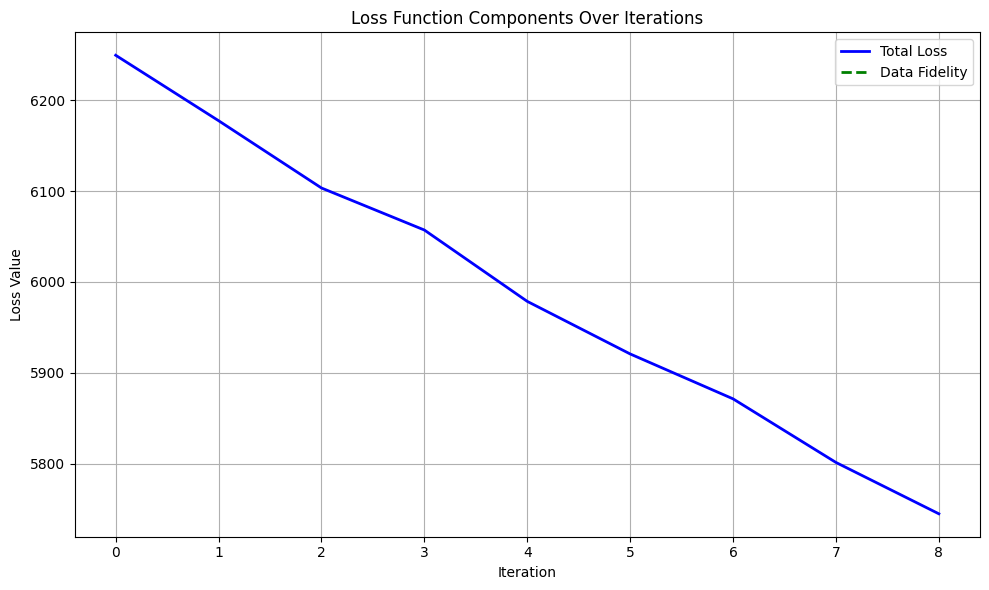

In [18]:
plot_loss_components(loss_hist,data_hist, f"loss_.png")


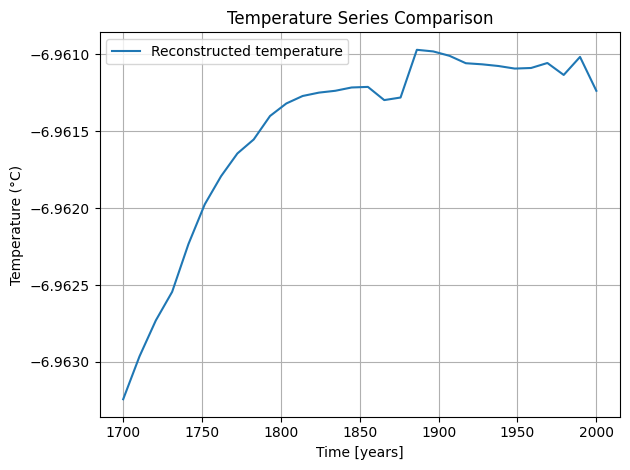

In [19]:
# Plot both in one figure
plt.figure()
# plt.plot(time_axis.numpy(), series.cpu().numpy(), marker='o', label='Synthetic temperature')
plt.plot(time_axis.numpy(), T_m_lowest.detach().cpu().numpy()-13.7, label='Reconstructed temperature')
# Add a red star at t=200, temp=9.0
# plt.plot([1857], [8.65], marker='*', markersize=14, color='red', label='Observstion1')
# plt.plot([1926], [9.0], marker='*', markersize=14, color='orange', label='Observstion2')

plt.title("Temperature Series Comparison")
plt.xlabel("Time [years]")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("temperatures_comparison.png")
plt.show()

In [20]:
H26,H57,H80,H99 = glacier_model(precip_tensor, T_m_lowest, T_s,P_daily=None,T_daily=None,melt_factor=melt_factor)  # Use the checkpointed glacier model


In [21]:
print(f"Difference {torch.sum(H26-obs_26)/torch.sum(obs_26) *100} ")
print(f"Difference {torch.sum(H57-obs_57)/torch.sum(obs_57) *100} ")
print(f"Difference {torch.sum(H80-obs_80)/torch.sum(obs_80) *100} ")
print(f"Difference {torch.sum(H99-obs_99)/torch.sum(obs_99) *100} ")


Difference -18.860065460205078 
Difference -6.517666816711426 
Difference -4.078110694885254 
Difference 1.8217185735702515 


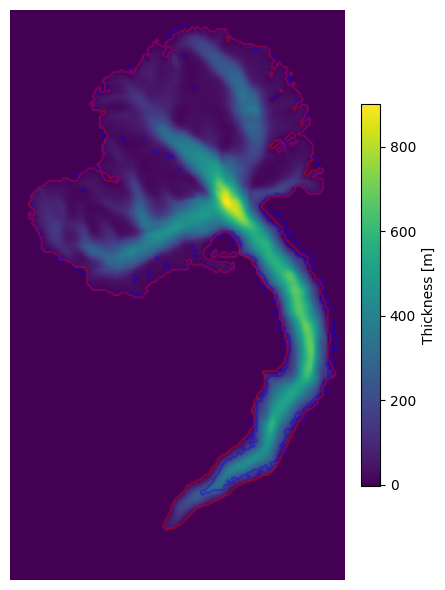

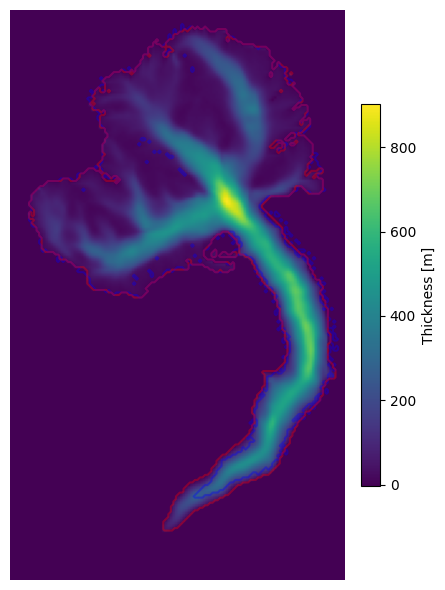

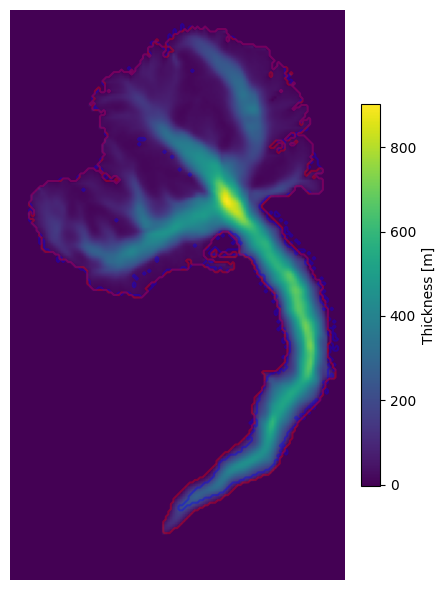

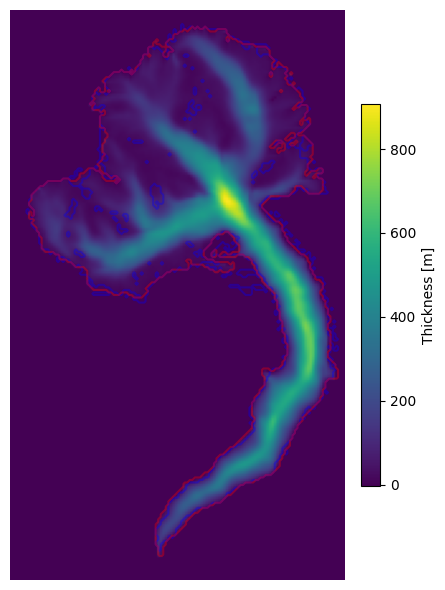

In [22]:
plot_sim_with_obs_extent(sim=H99, obs=obs_99,year=1999, thresh=1.0)   
plot_sim_with_obs_extent(sim=H80, obs=obs_80,year=1980, thresh=1.0)   
plot_sim_with_obs_extent(sim=H57, obs=obs_57,year=1957, thresh=1.0)   
plot_sim_with_obs_extent(sim=H26, obs=obs_26,year=1926, thresh=1.0)  

## Make a figure that justifies why we should invert for temperature and not precipitation


In [ ]:
# Load the file (the user mentioned skiprows=2 and known column order)
file_path = "temp_prec.dat"

# Load with numpy
arr = np.loadtxt(file_path, dtype=np.float32, skiprows=2)

# Create dataframe
df = pd.DataFrame(arr, columns=["year", "jd", "hour", "temp", "prec"])

In [ ]:
# Ensure types are clean
df["year"] = df["year"].astype(int)
df["jd"]   = df["jd"].astype(int)

# Sort just to be tidy
df = df.sort_values(["year", "jd"], kind="mergesort")

# Get the list of years in order and a mapping to indices
years = np.sort(df["year"].unique())
year_to_idx = {y: i for i, y in enumerate(years)}

# Initialize output: (n_years, 366 days, 2 vars [temp, prec])
out = np.zeros((len(years), 366, 2), dtype=np.float32)

# Clip JD to 1..366 just in case (optional safety)
jd = df["jd"].to_numpy()
jd = np.clip(jd, 1, 366)

# Vectorized placement:
yidx = df["year"].map(year_to_idx).to_numpy()
didx = jd - 1  # 0-based day index

out[yidx, didx, 0] = df["temp"].to_numpy(dtype=np.float32)  # temperature
out[yidx, didx, 1] = df["prec"].to_numpy(dtype=np.float32)  # precipitation

print(out.shape)   # should be (len(years), 366, 2)

In [ ]:
plt.figure()
# print(out[-1,:,1])
plt.plot(out[1,:,0]+18.0)
plt.plot(out[1,:,0]+11.0)
plt.plot(out[1,:,0]+4.0)
plt.plot(out[1,:,0])
plt.axhline(0, linestyle='--', linewidth=1)



In [ ]:
print((out[1,:,1]).sum())
print((out[2,:,1]).sum())
print((out[3,:,1]).sum())
print((out[4,:,1]).sum())


In [ ]:
thr=0.2


print(1.5/365*torch.clamp((out[1,:,0]+18.0) - thr, min=0).sum())
print(2/365*torch.clamp((out[1,:,0]+11.0) - thr, min=0).sum())
print(2/365*torch.clamp((out[1,:,0]+4.0) - thr, min=0).sum())
print(2/365*torch.clamp((out[1,:,0]) - thr, min=0).sum())


In [ ]:
print(df.head())

In [ ]:
# For rolling averages, choose window (e.g., 30 samples)
window = 30
df["temp_roll"] = df["temp"].rolling(window, center=True).mean()
df["prec_roll"] = df["prec"].rolling(window, center=True).mean()

# Create a time index (approximate: year + jd/365 + hour/8760)
time_index = df["year"] + (df["jd"] - 1)/365.0 + df["hour"]/8760.0

# Temperature figure
plt.figure(figsize=(10,4))
color = "C0"
plt.plot(time_index, df["temp"], color=color, alpha=0.6, label="Temperature")
plt.plot(time_index, df["temp_roll"], color=color, linewidth=2.5, label="Rolling Avg")
plt.xlabel("Year")
plt.ylabel("Temperature")
plt.legend()
plt.title("Temperature Evolution")
plt.show()

# Precipitation figure
plt.figure(figsize=(10,4))
color = "C1"
plt.plot(time_index, df["prec"], color=color, alpha=0.6, label="Precipitation")
plt.plot(time_index, df["prec_roll"], color=color, linewidth=2.5, label="Rolling Avg")
plt.xlabel("Year")
plt.ylabel("Precipitation")
plt.legend()
plt.title("Precipitation Evolution")
plt.show()
